# CSE 4095 — Class 10: Comparing Models Fairly
Use AI to help design and implement the workflow, but you must control the comparison.

## Setup
Imports and a first look at the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
# keep_default_na=False stops pandas from reading the category "None" as missing.
# Only truly blank cells become NaN.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student_id                    250 non-null    str    
 1   study_hours_per_week          241 non-null    float64
 2   sleep_hours_per_night         238 non-null    float64
 3   attendance_rate               250 non-null    float64
 4   practice_problems_per_week    250 non-null    int64  
 5   prior_programming_experience  243 non-null    str    
 6   study_group                   250 non-null    str    
 7   commute_minutes               250 non-null    int64  
 8   quiz_average                  250 non-null    float64
 9   exam_score                    250 non-null    float64
dtypes: float64(5), int64(2), str(3)
memory usage: 19.7 KB


In [4]:
df.isna().sum()

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

## Part 1 — Define the Classification Target
Create `high_exam_score`: "Yes" if `exam_score` >= 80, otherwise "No".

In [5]:
df["high_exam_score"] = np.where(df["exam_score"] >= 80, "Yes", "No")
df[["exam_score", "high_exam_score"]].head()

,exam_score,high_exam_score
0,64.6,No
1,81.5,Yes
2,92.0,Yes
3,100.0,Yes
4,68.5,No


In [6]:
class_counts = df["high_exam_score"].value_counts()
class_percents = df["high_exam_score"].value_counts(normalize=True) * 100

class_table = pd.DataFrame({"count": class_counts, "percent": class_percents.round(1)})
class_table

,count,percent
high_exam_score,,
No,151,60.4
Yes,99,39.6


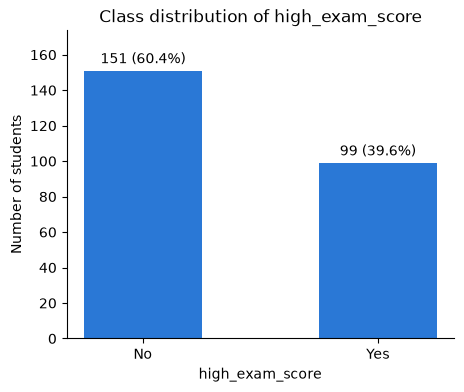

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(class_table.index, class_table["count"], width=0.5, color="#2a78d6")

# Label each bar with its count and percentage
labels = [f"{count} ({percent}%)" for count, percent in zip(class_table["count"], class_table["percent"])]
ax.bar_label(bars, labels=labels, padding=3)

ax.set_title("Class distribution of high_exam_score")
ax.set_xlabel("high_exam_score")
ax.set_ylabel("Number of students")
ax.set_ylim(0, class_table["count"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Part 1 Questions

**1. What are you trying to predict?**

**My answer:** We are trying to predict a high exam score. Whether a student gets a high score if exam_score >= 80. Prediction is made from student habits, before the exam happens. 

**2. Why is this a classification problem?**

**My answer:** This is a classification problem because the target has two discrete Yes and No labels. The model picks a category of these, not a number. 

**3. What percentage of students belong to each class?**

**My answer:** No = 60.4%, Yes = 39.6%

**4. Is the dataset approximately balanced?**

**My answer:** Not perfectly, it is a 60/40 split more or less. Mildly imbalanced

## Part 2 — Define X and y
Choose the feature columns, separate the features (X) from the target (y), and sort the features into numerical and categorical.

In [8]:
# Excluded on purpose: student_id, exam_score, and quiz_average are NOT features.
feature_columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

X = df[feature_columns]
y = df["high_exam_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250, 7)
y shape: (250,)


In [9]:
X.dtypes

study_hours_per_week            float64
sleep_hours_per_night           float64
attendance_rate                 float64
practice_problems_per_week        int64
prior_programming_experience        str
study_group                         str
commute_minutes                   int64
dtype: object

In [10]:
# Number columns are numerical. Text columns are categorical.
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['study_hours_per_week', 'sleep_hours_per_night', 'attendance_rate', 'practice_problems_per_week', 'commute_minutes']
Categorical features: ['prior_programming_experience', 'study_group']


### Part 2 Questions

**1. Why would using exam_score be target leakage?**

**My answer:** Using exam_score would be considered leakage because this isn't information the model has at the time of a prediction. THis model's purpose is TO predict exam_score, based on other features of students. Using exam_score would cause perfect accuracy in cross_validation, but tells you nothing about how habits relate to exam scores to learn further. 

## Part 3 — Train/Test Split
Split the data 80/20. `stratify=y` keeps the same Yes/No mix in both sets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (200, 7)
X_test:  (50, 7)
y_train: (200,)
y_test:  (50,)


In [12]:
# Class percentages should be nearly the same in all three columns
split_percents = pd.DataFrame({
    "full data": y.value_counts(normalize=True) * 100,
    "y_train": y_train.value_counts(normalize=True) * 100,
    "y_test": y_test.value_counts(normalize=True) * 100,
}).round(1)
split_percents

,full data,y_train,y_test
high_exam_score,,,
No,60.4,60.5,60.0
Yes,39.6,39.5,40.0


> ⚠️ **The test set is now locked away until Part 15.**
>
> `X_test` and `y_test` are not used for any model comparison, tuning, or experiment before Part 15. Every comparison from here on uses cross-validation on the training set only.

### Part 3 Questions

**1. Why are we holding the test set aside?**

**My answer:**

**2. What could happen if we repeatedly check test accuracy while modifying our model?**

**My answer:**

## 4. Baseline
Create a majority-class baseline for classification or mean baseline for regression.

In [13]:
# TODO: baseline


## 5. Preprocessing pipeline
Handle missing values and categorical variables.

In [14]:
# TODO: preprocessing setup


## 6. Cross-validation comparison
Compare a small set of models using the same folds and metrics.

In [15]:
# TODO: cross-validation model comparison


## 7. Tune one hyperparameter
Tune decision-tree max_depth using cross-validation on the training data.

In [16]:
# TODO: tune max_depth


## 8. Final test evaluation
Choose one workflow, fit on full training data, and evaluate once on the test set.

In [17]:
# TODO: final test evaluation


## 9. Error analysis
Classification: false positives/false negatives. Regression: largest residuals.

In [18]:
# TODO: error analysis


## 10. Conclusion and AI Reflection
Summarize your evidence. Describe one AI suggestion you rejected or modified and why.